# E91 RL advanced — RecurrentPPO + MPC (DIQKD analog of `QKD_experiment_6`)

Two new agents to compare against vanilla PPO from `QKD_experiment_5_E91`:

1. **RecurrentPPO** — LSTM policy with hidden state across the episode. Tests whether the OU-near-cliff regime is recoverable with memory of recent noise/action history.
2. **MPC (Monte Carlo planning)** — at each step, sample OU rollouts forward and pick the action that maximizes mean χ over the rollouts subject to projected feasibility. Model-based planning, no learning.

Compared against:
- **DP (analytical)** — Bellman-optimal over library
- **Oracle (greedy)** — windowed-projected feasibility
- **Identity** — honest Bell pair

Same library as `QKD_experiment_5_E91.ipynb` (7 levels × 4 anchors = 26 cells + identity).

## Imports

In [1]:
import os, math, pickle, time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import gymnasium as gym
from gymnasium import spaces
from sb3_contrib import RecurrentPPO
from stable_baselines3.common.callbacks import BaseCallback

import pathB_lib as L
from pathB_lib import (DET_THRESH, P_INTERP, EPISODE_LEN, P_MU, P_KAPPA, P_SIGMA,
                       P_MIN, P_MAX, WIN_S, PathBEnv, run_episode, summarize_runs,
                       compute_holevo_and_S_noisy)
from numpy.polynomial.hermite_e import hermegauss

torch.set_default_dtype(torch.float32)

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


## Config + load 7-level library + (S, χ) tables

In [2]:
# Use the 7-level library built for exp_5_E91
from evoluspsa_e91 import circuit_to_unitary, STD_SETTINGS
library = pickle.load(open('e91_library_pathB_7levels.pkl', 'rb'))
torch.set_default_dtype(torch.float64)
C_dt = torch.complex128

# action 0 = identity (honest Bell pair)
phi_plus_e0 = torch.zeros(8, dtype=C_dt)
phi_plus_e0[0] = 1 / math.sqrt(2); phi_plus_e0[6] = 1 / math.sqrt(2)
M_init = torch.randn(8, 8, dtype=C_dt) + 1j * torch.randn(8, 8, dtype=C_dt)
M_init[:, 0] = phi_plus_e0
Q, _ = torch.linalg.qr(M_init); Q[:, 0] = phi_plus_e0
U_star = Q

action_U = [U_star]
action_settings = [np.array(STD_SETTINGS)]
action_meta = [{'label': 'identity', 'lvl': None, 'p_anchor': None}]
for (p_anchor, lvl), entry in library.items():
    action_U.append(circuit_to_unitary(entry['circuit']))
    action_settings.append(np.array(entry['settings']))
    action_meta.append({'label': f'{lvl}_p{p_anchor:.3f}', 'lvl': lvl, 'p_anchor': p_anchor})
N_ACTIONS = len(action_U)

S_TBL = np.zeros((N_ACTIONS, len(P_INTERP)))
CHI_TBL = np.zeros((N_ACTIONS, len(P_INTERP)))
for a in range(N_ACTIONS):
    for j, p in enumerate(P_INTERP):
        S, chi = compute_holevo_and_S_noisy(action_U[a], action_settings[a], float(p))
        S_TBL[a, j] = S; CHI_TBL[a, j] = chi

torch.set_default_dtype(torch.float32)
print(f'N_ACTIONS = {N_ACTIONS}  (1 identity + {N_ACTIONS-1} cells)')
print(f'DET_THRESH = {DET_THRESH:.4f}')

N_ACTIONS = 27  (1 identity + 26 cells)
DET_THRESH = 2.4440


## Environment (augmented obs with cum_S headroom features)

In [3]:
env_kwargs = dict(viol_coef=3.0, det_penalty=30.0, augmented_obs=True)
test_env = PathBEnv(S_TBL, CHI_TBL, **env_kwargs)
print(f'obs_dim = {test_env.observation_space.shape[0]}')

obs_dim = 9


## DP (analytical reference)

Same backward induction as `QKD_experiment_5_E91`, kept here so the notebook is self-contained.

In [4]:
N_PBIN = len(P_INTERP); P_BINS = P_INTERP
def run_dp(N_SBIN=250, DET_PEN=30.0, T=EPISODE_LEN):
    S_BINS = np.linspace(0, T*2*math.sqrt(2)+5, N_SBIN)
    GH_NODES, GH_W = hermegauss(7); GH_W = GH_W / np.sqrt(2*math.pi)
    decay = np.exp(-P_KAPPA)
    noise_std = P_SIGMA * np.sqrt((1 - np.exp(-2*P_KAPPA)) / (2*P_KAPPA))
    TRANS_p = np.zeros((N_PBIN, len(GH_NODES)), dtype=np.int32)
    TRANS_w = np.zeros((N_PBIN, len(GH_NODES)))
    for i in range(N_PBIN):
        p_mean = P_MU + (P_BINS[i] - P_MU) * decay
        for k, (n, w) in enumerate(zip(GH_NODES, GH_W)):
            p_next = float(np.clip(p_mean + noise_std*n, P_MIN, P_MAX))
            TRANS_p[i, k] = int(np.argmin(np.abs(P_BINS - p_next)))
            TRANS_w[i, k] = w
    V = np.zeros((T+1, N_PBIN, N_SBIN)); PI = np.zeros((T, N_PBIN, N_SBIN), dtype=np.int8)
    budget = T * DET_THRESH
    for s_idx in range(N_SBIN):
        if S_BINS[s_idx] < budget: V[T, :, s_idx] = -DET_PEN
    for t in range(T-1, -1, -1):
        EV = np.zeros((N_PBIN, N_SBIN))
        for p_idx in range(N_PBIN):
            for k in range(len(GH_NODES)):
                EV[p_idx] += TRANS_w[p_idx, k] * V[t+1, TRANS_p[p_idx, k], :]
        for p_idx in range(N_PBIN):
            S_acts = S_TBL[:, p_idx]; chi_acts = CHI_TBL[:, p_idx]
            s_new = S_BINS[:, None] + S_acts[None, :]
            EV_interp = np.interp(s_new.ravel(), S_BINS, EV[p_idx]).reshape(s_new.shape)
            Q = chi_acts[None, :] + EV_interp
            best_a = np.argmax(Q, axis=1)
            V[t, p_idx, :] = Q[np.arange(N_SBIN), best_a]
            PI[t, p_idx, :] = best_a.astype(np.int8)
    return V, PI, S_BINS
print('Running DP...')
V, PI, S_BINS = run_dp()
print('Done')

Running DP...
Done


## Training — RecurrentPPO (LSTM policy)

In [5]:
TRAIN_STEPS = 200_000
EVAL_EVERY  = 25_000

def evaluate_recurrent(model, n_episodes=20):
    env = PathBEnv(S_TBL, CHI_TBL, **env_kwargs)
    chis, dets = [], 0
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=10_000+ep); done = False
        lstm_state = None; episode_start = np.array([True])
        while not done:
            a, lstm_state = model.predict(obs, state=lstm_state,
                                          episode_start=episode_start, deterministic=True)
            episode_start = np.array([False])
            obs, _, done, _, info = env.step(int(a))
        chis.append(np.mean(env.chi_ep))
        if info.get('detected'): dets += 1
    return float(np.mean(chis)), dets/n_episodes

class EvalCB(BaseCallback):
    def __init__(self):
        super().__init__()
        self.best_score = -1e9; self.history = []
    def _on_step(self):
        if self.num_timesteps % EVAL_EVERY == 0:
            try:
                m, d = evaluate_recurrent(self.model, n_episodes=20)
                self.history.append({'step': self.num_timesteps, 'chi': m, 'det': d})
                score = m - 2.0 * d
                if score > self.best_score and d <= 0.05:
                    self.best_score = score
                    self.model.save('best_rppo_e91')
                if self.num_timesteps % 100_000 == 0:
                    print(f'  [Eval @ {self.num_timesteps:>7,}] χ={m:.4f} det={d*100:.1f}%')
            except Exception as e:
                print(f'  Eval error: {e}')
        return True

train_env = PathBEnv(S_TBL, CHI_TBL, **env_kwargs)
best_cb = EvalCB()
model = RecurrentPPO('MlpLstmPolicy', train_env, verbose=0, device='cpu',
                     learning_rate=3e-4, n_steps=512, batch_size=128, n_epochs=10,
                     gamma=0.99, ent_coef=0.05, clip_range=0.2, seed=42,
                     policy_kwargs=dict(lstm_hidden_size=128,
                                        net_arch=dict(pi=[128, 128], vf=[128, 128])))
t0 = time.time()
model.learn(total_timesteps=TRAIN_STEPS, callback=best_cb)
print(f'RecurrentPPO trained in {(time.time()-t0)/60:.1f} min')
if os.path.exists('best_rppo_e91.zip'):
    model = RecurrentPPO.load('best_rppo_e91'); print('Loaded best model')

  [Eval @ 100,000] χ=0.3299 det=25.0%


  [Eval @ 200,000] χ=0.2787 det=0.0%


RecurrentPPO trained in 25.3 min


Loaded best model


## MPC — Monte Carlo OU rollouts

At each step, sample $N$ futures (OU paths $\times$ greedy action choices), pick the action whose first-step + mean-future-χ is highest among feasible candidates.

In [6]:
MPC_HORIZON = 5
MPC_SAMPLES = 20

decay = np.exp(-P_KAPPA)
noise_std = P_SIGMA * np.sqrt((1 - np.exp(-2*P_KAPPA)) / (2*P_KAPPA))

def sample_ou_path(p_now, horizon, n, rng):
    paths = np.zeros((n, horizon))
    p = np.full(n, p_now)
    for h in range(horizon):
        p = np.clip(P_MU + (p - P_MU)*decay + noise_std * rng.standard_normal(n), P_MIN, P_MAX)
        paths[:, h] = p
    return paths

def oracle_step(p_now, window):
    """Oracle: max chi action whose projected windowed mean S stays >= DET_THRESH."""
    win = window[-(WIN_S - 1):]
    sum_past = float(np.sum(win)) if win else 0.0
    n_win = len(win) + 1
    best_a, best_chi = 0, -np.inf
    for ai in range(N_ACTIONS):
        S_ai = float(np.interp(p_now, P_INTERP, S_TBL[ai]))
        chi_ai = float(np.interp(p_now, P_INTERP, CHI_TBL[ai]))
        if (sum_past + S_ai)/n_win >= DET_THRESH and chi_ai > best_chi:
            best_chi, best_a = chi_ai, ai
    if best_chi < 0:
        best_a = int(np.argmax([float(np.interp(p_now, P_INTERP, S_TBL[a])) for a in range(N_ACTIONS)]))
        best_chi = float(np.interp(p_now, P_INTERP, CHI_TBL[best_a]))
    return best_a, best_chi, float(np.interp(p_now, P_INTERP, S_TBL[best_a]))

def mpc_policy(obs, env):
    """1-step lookahead with Oracle as continuation policy.

    For each candidate first action a (that passes immediate windowed-feasibility),
    sample MPC_SAMPLES OU trajectories, run Oracle for MPC_HORIZON future steps,
    accumulate chi. Pick a maximizing mean total chi while respecting the
    projected episode-mean S constraint.
    """
    p_now = float(obs[0])
    past = env.S_ep[-(WIN_S - 1):]
    sum_past = float(np.sum(past)) if past else 0.0
    n_win = len(past) + 1
    rng = np.random.default_rng(env.t * 1000 + 42)
    paths = sample_ou_path(p_now, MPC_HORIZON, MPC_SAMPLES, rng)
    cum_S_so_far = float(np.sum(env.S_ep))
    steps_remaining = EPISODE_LEN - env.t
    # Projected episode-mean S after this step + remaining oracle steps.
    # Lower bound: assume oracle delivers DET_THRESH on average for remaining steps.
    # Constraint: (cum_S_so_far + S_a + (steps_remaining-1) * S_oracle_avg) / EPISODE_LEN >= DET_THRESH

    best_a, best_score = -1, -np.inf
    for a in range(N_ACTIONS):
        S_a = float(np.interp(p_now, P_INTERP, S_TBL[a]))
        chi_a = float(np.interp(p_now, P_INTERP, CHI_TBL[a]))
        # Immediate windowed feasibility (loose check)
        if (sum_past + S_a)/n_win < DET_THRESH - 0.05:
            continue
        # Run Oracle continuation across MPC_SAMPLES rollouts
        chi_total_samples = []
        S_total_samples = []
        for s in range(MPC_SAMPLES):
            window = list(past) + [S_a]
            cum_chi = chi_a; cum_S_local = S_a
            for h in range(MPC_HORIZON):
                p_h = paths[s, h]
                a_h, chi_h, S_h = oracle_step(p_h, window)
                window.append(S_h)
                cum_chi += chi_h; cum_S_local += S_h
            chi_total_samples.append(cum_chi)
            S_total_samples.append(cum_S_local)
        mean_chi = float(np.mean(chi_total_samples))
        mean_S_path = float(np.mean(S_total_samples))
        # Penalty if projected episode-mean S < threshold
        # Assume after MPC_HORIZON, Oracle continues at threshold
        n_path = 1 + MPC_HORIZON
        n_post = steps_remaining - n_path
        if n_post < 0: n_post = 0
        proj_episode_S = (cum_S_so_far + mean_S_path + n_post * DET_THRESH) / EPISODE_LEN
        score = mean_chi - 30.0 * max(0, DET_THRESH - proj_episode_S)
        if score > best_score:
            best_score = score; best_a = a
    return best_a if best_a >= 0 else 0

print('MPC policy (Oracle continuation, 1-step lookahead) ready')


MPC policy (Oracle continuation, 1-step lookahead) ready


## Evaluation: RecurrentPPO vs MPC vs DP vs Oracle vs Identity

In [7]:
def rppo_policy(obs, env, _state={'lstm': None, 'starts': None}):
    if _state['starts'] is None:
        _state['lstm'] = None; _state['starts'] = np.array([True])
    a, _state['lstm'] = model.predict(obs, state=_state['lstm'],
                                       episode_start=_state['starts'], deterministic=True)
    _state['starts'] = np.array([False])
    return int(a)

def dp_policy(obs, env):
    p_idx = int(np.argmin(np.abs(P_BINS - float(obs[0]))))
    s_idx = int(np.argmin(np.abs(S_BINS - float(np.sum(env.S_ep)))))
    return int(PI[env.t, p_idx, s_idx])

def oracle_policy(obs, env):
    p_now = float(obs[0])
    past = env.S_ep[-(WIN_S - 1):]
    sum_past = float(np.sum(past)) if past else 0.0
    n = len(past) + 1
    best_a, best_chi = 0, -np.inf
    for a in range(N_ACTIONS):
        S_a = float(np.interp(p_now, P_INTERP, S_TBL[a]))
        chi_a = float(np.interp(p_now, P_INTERP, CHI_TBL[a]))
        if (sum_past + S_a)/n >= DET_THRESH and chi_a > best_chi:
            best_chi = chi_a; best_a = a
    if best_chi < 0:
        best_a = int(np.argmax([float(np.interp(p_now, P_INTERP, S_TBL[a])) for a in range(N_ACTIONS)]))
    return best_a

def identity_policy(obs, env): return 0

def reset_rppo_state():
    rppo_policy.__defaults__[0]['lstm'] = None
    rppo_policy.__defaults__[0]['starts'] = None

def run_episode_with_reset(policy_fn, env_seed):
    if policy_fn is rppo_policy: reset_rppo_state()
    return run_episode(PathBEnv(S_TBL, CHI_TBL, **env_kwargs), policy_fn, env_seed=env_seed)

POLICIES = {'RecurrentPPO': rppo_policy, 'MPC': mpc_policy,
            'DP': dp_policy, 'Oracle': oracle_policy, 'Identity': identity_policy}

TEST_EPS = 100
results = {}
for name, pol in POLICIES.items():
    runs = []
    for ep in range(TEST_EPS):
        if pol is rppo_policy: reset_rppo_state()
        env = PathBEnv(S_TBL, CHI_TBL, **env_kwargs)
        runs.append(run_episode(env, pol, env_seed=20_000+ep))
    summary = summarize_runs(runs)
    actions = np.concatenate([r['actions'] for r in runs])
    results[name] = {'summary': summary, 'actions': actions.tolist(),
                     'n_unique': len(np.unique(actions))}

rows = []
for name, r in results.items():
    s = r['summary']
    rows.append({'Method': name,
                 'Mean χ': f"{s['mean_chi']:.4f}",
                 'Std χ':  f"{s['std_chi']:.4f}",
                 'Mean S': f"{s['mean_S']:.4f}",
                 'Det %':  f"{s['det_rate']*100:.1f}%",
                 'Distinct actions': r['n_unique']})
pd.DataFrame(rows).set_index('Method')

,Mean χ,Std χ,Mean S,Det %,Distinct actions
Method,,,,,
RecurrentPPO,0.2801,0.0329,2.5083,0.0%,4
MPC,0.3511,0.0677,2.4481,0.0%,15
DP,0.3520,0.0677,2.4484,6.0%,24
Oracle,0.3495,0.0710,2.4463,0.0%,17
Identity,0.0000,0.0000,2.6604,0.0%,1


## Plots

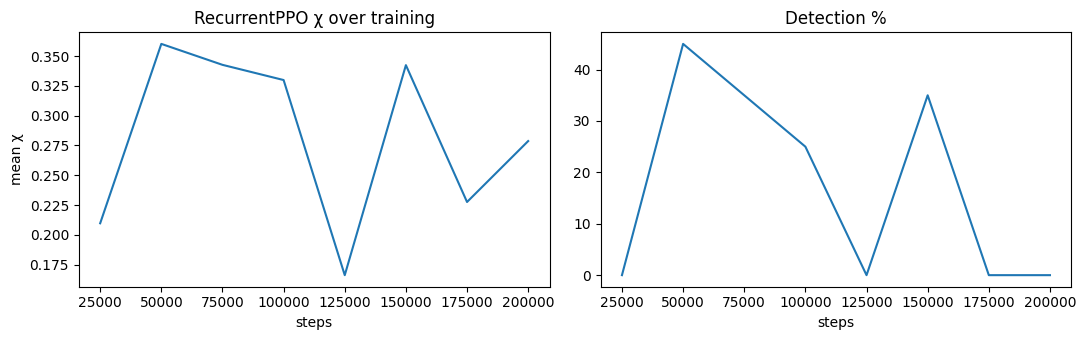

In [8]:
if best_cb.history:
    hist = pd.DataFrame(best_cb.history)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(hist['step'], hist['chi']); ax[0].set_title('RecurrentPPO χ over training')
    ax[0].set_xlabel('steps'); ax[0].set_ylabel('mean χ')
    ax[1].plot(hist['step'], hist['det']*100); ax[1].set_title('Detection %')
    ax[1].set_xlabel('steps')
    plt.tight_layout(); plt.show()

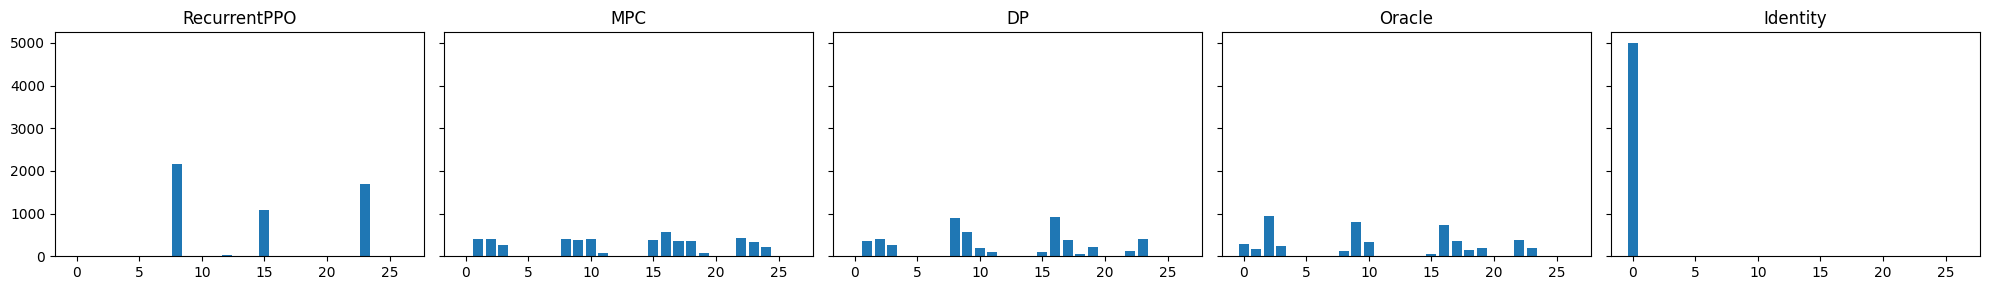

In [9]:
fig, axes = plt.subplots(1, len(POLICIES), figsize=(4*len(POLICIES), 3), sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    counts = np.bincount(r['actions'], minlength=N_ACTIONS)
    ax.bar(range(N_ACTIONS), counts)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## Save

In [10]:
with open('e91_exp6_results.pkl', 'wb') as f:
    pickle.dump({'results': results, 'history': best_cb.history,
                 'config': {'TRAIN_STEPS': TRAIN_STEPS,
                            'MPC_HORIZON': MPC_HORIZON, 'MPC_SAMPLES': MPC_SAMPLES}}, f)
print('Saved e91_exp6_results.pkl')

Saved e91_exp6_results.pkl
